In [8]:
import pandas as pd
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
df.shape

(303, 14)

In [4]:
df.columns

Index(['age', 'sex', 'cp', 'trtbps', 'chol', 'fbs', 'restecg', 'thalachh',
       'exng', 'oldpeak', 'slp', 'caa', 'thall', 'output'],
      dtype='object')

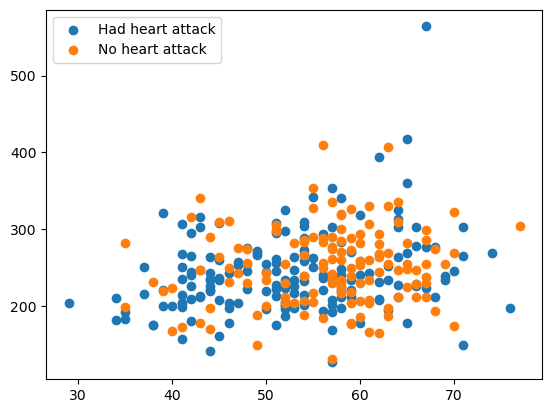

In [28]:
import matplotlib.pyplot as plt
df_attack = df[df.output == 1]
df_none = df[df.output == 0]
plt.scatter(df_attack.age, df_attack.chol, label = "Had heart attack")
plt.scatter(df_none.age, df_none.chol, label = "No heart attack")
plt.legend()

In [29]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

X = df[['age', 'sex', 'cp', 'trtbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exng', 'oldpeak', 'slp', 'caa', 'thall']]
y = df.output
print(df.shape)
print(X.shape)
print(y.shape)



(303, 14)
(303, 13)
(303,)


In [31]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=.3)
print(Xtrain.shape)

(212, 13)


In [44]:
classifier = DecisionTreeClassifier(criterion="entropy")
classifier.fit(Xtrain, ytrain)

DecisionTreeClassifier(criterion='entropy')

In [45]:
ypred = classifier.predict(Xtest)
ypredtrain = classifier.predict(Xtrain)
from sklearn.metrics import accuracy_score
print("test accuracy: ", accuracy_score(ypred, ytest))
print("train accuracy: ", accuracy_score(ypredtrain, ytrain))

test accuracy:  0.7802197802197802
train accuracy:  1.0


In [42]:
classifier = DecisionTreeClassifier(criterion="entropy", max_depth=4)
classifier.fit(Xtrain, ytrain)
ypred = classifier.predict(Xtest)
ypredtrain = classifier.predict(Xtrain)
print("test accuracy: ", accuracy_score(ypred, ytest))
print("train accuracy: ", accuracy_score(ypredtrain, ytrain))

test accuracy:  0.8241758241758241
train accuracy:  0.8773584905660378
